# Notebook 2: Question Answering and Its Evaluation Metrics

**What you will do:** build question answering systems (a from-scratch retrieval + extraction system, and a real transformer on Colab) and evaluate them with the metrics from the presentation: **Exact Match**, **F1**, the **SQuAD 2.0** protocol for unanswerable questions, **why exact match fails with verbose (LLM-style) answers**, **LLM-as-a-judge** agreement (Cohen's kappa), and **RAG-style metrics** (faithfulness, relevance).

| Part | Content | Needs internet / GPU? |
|---|---|---|
| 1 | Data: 4 passages, 27 questions (19 answerable, 8 unanswerable) | no |
| 2 | EM and F1 from scratch (official SQuAD normalisation) | no |
| 3 | A QA system from scratch: retrieve a sentence, extract the answer | no |
| 4 | SQuAD 2.0 protocol: HasAns / NoAns, no-answer threshold, `best_f1` | no |
| 5 | A real QA model (RoBERTa-SQuAD2) with automatic fallback | optional (Colab) |
| 6 | Why exact match fails: verbose answers, rules, and an LLM judge (kappa) | judge optional |
| 7 | RAG metrics: faithfulness, answer relevance, context precision and recall | no |
| 8 | Bootstrap confidence intervals | no |

**Safe by design:** model cells are wrapped in `try/except` and fall back automatically, so **Run all** always works. Set `USE_MODELS = False` to skip neural models on purpose.

*Passages and names are fictional, written for this notebook.*

In [1]:
# Colab only: libraries (transformers and torch are preinstalled on Colab).
!pip -q install scikit-learn pandas matplotlib

In [2]:
import re, math, string, random, collections
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import cohen_kappa_score

pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 90)
random.seed(0); np.random.seed(0)
USE_MODELS = True   # set False to skip all neural models
print("Setup OK")

Setup OK


## Part 1: Data

Four short passages, each with questions. Some questions are **unanswerable from the passage** (empty gold list), as in SQuAD 2.0: the system must say "no answer".

In [3]:
PASSAGES = {
 "bridge": "The Harbour Bridge in Marlow opened in 1932 after six years of construction. It was designed by the engineer Lucia Ferreira and spans 503 metres across the Tern River. At the time it was the longest steel arch bridge in the country. More than 40,000 vehicles cross it every day. A major renovation in 2011 cost 85 million euros and replaced the original deck.",
 "photo": "Photosynthesis is the process by which plants convert light energy into chemical energy. It takes place mainly in the chloroplasts, which contain the green pigment chlorophyll. The process uses carbon dioxide and water and releases oxygen as a by-product. Most of the oxygen in the atmosphere was produced this way. Photosynthesis was first described in detail by Jan Ingenhousz in 1779.",
 "rail": "Nordic Rail was founded in 1954 by Henrik Larsen in the city of Oslund. The company started with 12 locomotives and now operates 310 trains on 28 routes. Its headquarters moved to Brenna in 1987. In 2019 it carried 95 million passengers, a record year. The current chief executive is Ingrid Solheim.",
 "lake": "Lake Tessel is the largest lake in the Valmont region, covering 1,240 square kilometres. It is fed by three rivers and drains into the sea through the Orla River. The deepest point of the lake is 310 metres. The town of Sandvik sits on its northern shore and is known for its annual fishing festival. The lake freezes completely about once every ten years.",
}
QA = [
 ("bridge", "Who designed the Harbour Bridge?", ["Lucia Ferreira", "the engineer Lucia Ferreira"]),
 ("bridge", "When did the bridge open?", ["1932"]),
 ("bridge", "How long is the bridge?", ["503 metres"]),
 ("bridge", "Which river does the bridge cross?", ["Tern River", "the Tern River"]),
 ("bridge", "How much did the 2011 renovation cost?", ["85 million euros"]),
 ("bridge", "Who paid for the construction of the bridge?", []),
 ("bridge", "How many people died during the construction?", []),
 ("photo", "Where does photosynthesis mainly take place?", ["chloroplasts", "in the chloroplasts"]),
 ("photo", "Which pigment makes plants green?", ["chlorophyll"]),
 ("photo", "What gas is released as a by-product?", ["oxygen"]),
 ("photo", "Who first described photosynthesis in detail?", ["Jan Ingenhousz"]),
 ("photo", "What temperature is needed for photosynthesis?", []),
 ("photo", "Which scientist won a Nobel Prize for photosynthesis?", []),
 ("rail", "Who founded Nordic Rail?", ["Henrik Larsen"]),
 ("rail", "How many trains does the company operate?", ["310", "310 trains"]),
 ("rail", "When did the headquarters move to Brenna?", ["1987"]),
 ("rail", "How many passengers did it carry in 2019?", ["95 million", "95 million passengers"]),
 ("rail", "Who is the chief executive?", ["Ingrid Solheim"]),
 ("rail", "How many employees does Nordic Rail have?", []),
 ("rail", "Where is the largest depot located?", []),
 ("lake", "How large is Lake Tessel?", ["1,240 square kilometres"]),
 ("lake", "Which river drains the lake into the sea?", ["Orla River", "the Orla River"]),
 ("lake", "How deep is the deepest point?", ["310 metres"]),
 ("lake", "Which town is on the northern shore?", ["Sandvik"]),
 ("lake", "How often does the lake freeze completely?", ["about once every ten years", "once every ten years"]),
 ("lake", "Who built the first harbour on the lake?", []),
 ("lake", "How many fish species live in the lake?", []),
]
ITEMS = [dict(id=i, pid=p, question=q, answers=a, has_answer=len(a) > 0) for i, (p, q, a) in enumerate(QA)]
print(len(ITEMS), "questions;", sum(it["has_answer"] for it in ITEMS), "answerable;", sum(not it["has_answer"] for it in ITEMS), "unanswerable")
for it in ITEMS[:3] + ITEMS[5:6]:
    print(f"  Q: {it['question']:48s} gold: {it['answers']}")

27 questions; 19 answerable; 8 unanswerable
  Q: Who designed the Harbour Bridge?                 gold: ['Lucia Ferreira', 'the engineer Lucia Ferreira']
  Q: When did the bridge open?                        gold: ['1932']
  Q: How long is the bridge?                          gold: ['503 metres']
  Q: Who paid for the construction of the bridge?     gold: []


## Part 2: Exact Match and F1 from scratch

The official **SQuAD** evaluation (Rajpurkar et al., 2016):

1. **Normalise** both strings: lowercase, remove punctuation, remove the articles *a, an, the*, collapse spaces.
2. **Exact Match (EM)** = 1 if the normalised prediction equals the normalised gold answer, else 0.
3. **F1** = token overlap: precision = common tokens / predicted tokens, recall = common tokens / gold tokens, F1 = 2PR/(P+R).
4. With several gold answers take the **maximum** over them, then average over questions.
5. **SQuAD 2.0:** for an unanswerable question the gold is empty; the score is 1 only if the system also answers nothing.

In [4]:
def normalize_answer(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def f1_pair(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    if len(p) == 0 or len(g) == 0:                  # unanswerable convention (official v2 script)
        return float(p == g)
    same = sum((Counter(p) & Counter(g)).values())
    if same == 0:
        return 0.0
    prec, rec = same / len(p), same / len(g)
    return 2 * prec * rec / (prec + rec)

def em_pair(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def best_over_golds(fn, pred, golds):
    golds = golds if golds else [""]               # empty gold list = "no answer expected"
    return max(fn(pred, g) for g in golds)

# ---- the table from slide 6 ---------------------------------------------------------------
rows = [("the Eiffel Tower", "Eiffel Tower"), ("Obama", "Barack Obama"), ("in 1976", "1976"),
        ("Napoleon", "Napoleon Bonaparte"), ("Lyon", "Paris")]
df = pd.DataFrame([[p, g, em_pair(p, g), round(f1_pair(p, g), 3)] for p, g in rows], columns=["prediction", "gold", "EM", "F1"])
display(df)
assert df["EM"].tolist() == [1, 0, 0, 0, 0]
assert df["F1"].round(2).tolist() == [1.0, 0.67, 0.67, 0.67, 0.0]
print("Matches slide 6: the article is removed (EM 1), partial credit 0.67, no overlap 0.00")
print("Unanswerable: pred '' vs gold [] ->", best_over_golds(f1_pair, "", []), "| pred 'Paris' vs gold [] ->", best_over_golds(f1_pair, "Paris", []))

,prediction,gold,EM,F1
0,the Eiffel Tower,Eiffel Tower,1.0,1.000
1,Obama,Barack Obama,0.0,0.667
2,in 1976,1976,0.0,0.667
3,Napoleon,Napoleon Bonaparte,0.0,0.667
4,Lyon,Paris,0.0,0.000


Matches slide 6: the article is removed (EM 1), partial credit 0.67, no overlap 0.00
Unanswerable: pred '' vs gold [] -> 1.0 | pred 'Paris' vs gold [] -> 0.0


## Part 3: A question answering system from scratch

No neural network, so you can see every step:

1. **Retrieve** the passage sentence that best matches the question (IDF-weighted overlap of content words).
2. **Detect the question type** (who, when, how many, where, which...).
3. **Extract** a candidate of the right type from that sentence (a name, a year, a number with its unit, a place).
4. **Confidence** = how much of the question the sentence covers. Low confidence means "no answer".

It is deliberately simple, so it makes realistic mistakes (wrong sentence, wrong span) that we can analyse with the metrics.

In [5]:
STOP = set("a an the of to in on at by for and or but is are was were be been it its this that these those with as from "
           "who whom whose what which when where why how many much long large deep often does do did has have had can will "
           "first current".split())
FUNC = set("across in at and on of the by to for with after since it a an as from into through is are was were".split())

def stem(w):
    return w[:4] if len(w) > 4 else w            # crude prefix stemmer: moved~move, trains~train, designed~design

def content_words(text):
    return [stem(w) for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

def split_sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s.strip()]

# IDF over all passage sentences
ALL_SENTS = [s for p in PASSAGES.values() for s in split_sentences(p)]
DF = Counter(w for s in ALL_SENTS for w in set(content_words(s)))
N_S = len(ALL_SENTS)
def idf(w):
    return math.log((N_S + 1) / (DF.get(w, 0) + 1)) + 1

def retrieve(question, passage):
    qw = content_words(question)
    sents = split_sentences(passage)
    best, best_score = None, -1.0
    for s in sents:
        sw = set(content_words(s))
        denom = sum(idf(w) for w in qw) or 1.0
        score = sum(idf(w) for w in qw if w in sw) / denom
        if score > best_score:
            best, best_score = s, score
    return best, best_score

def qtype(q):
    ql = q.lower()
    if re.search(r"\bhow often\b", ql): return "frequency"
    if re.search(r"\bhow (many|much|long|large|deep|far|big|tall|high)\b", ql): return "quantity"
    if re.search(r"\bwhen\b|\bwhat year\b", ql): return "year"
    if re.search(r"\bwho(m|se)?\b", ql): return "person"
    if re.search(r"\bwhere\b", ql): return "place"
    return "entity"

def cap_sequences(sentence, exclude):
    out = []
    for m in re.finditer(r"\b[A-Z][\w\-]*(?:\s+[A-Z][\w\-]*)*", sentence):
        toks = m.group(0).split()
        if m.start() == 0 and toks[0].lower() in STOP | {"it", "its"}:
            toks = toks[1:]
        if not toks:
            continue
        if all(re.sub(r"\W", "", t.lower()) in exclude for t in toks):
            continue
        out.append(" ".join(toks))
    return out

def number_phrases(sentence, qwords):
    toks = sentence.split()
    out = []
    for i, t in enumerate(toks):
        c = t.strip(".,;:!?")
        if re.fullmatch(r"\d[\d,]*(\.\d+)?", c) and c not in qwords:
            phrase = [c]
            j = i + 1
            while j < len(toks) and len(phrase) < 4:
                nxt = toks[j].strip(".,;:!?")
                if nxt.lower() in FUNC or not nxt.isalpha() or toks[j - 1][-1] in ".,;:!?":
                    break
                phrase.append(nxt); j += 1
            out.append(" ".join(phrase))
    return out

def extract_answer(question, sentence):
    qt = qtype(question)
    qtoks = set(re.findall(r"[a-z0-9,]+", question.lower()))
    qstems = set(content_words(question))
    if qt == "frequency":
        m = re.search(r"(?:about |roughly )?(?:once|twice) every [a-z]+ [a-z]+", sentence.lower())
        return m.group(0) if m else ""
    if qt == "quantity":
        cands = number_phrases(sentence, qtoks)
        if not cands:
            return ""
        def overlap(c): return len({stem(w) for w in re.findall(r"[a-z]+", c.lower())} & qstems)
        return max(cands, key=lambda c: (overlap(c), -cands.index(c)))
    if qt == "year":
        yrs = [y for y in re.findall(r"\b(?:1\d{3}|20\d{2})\b", sentence) if y not in qtoks]
        return yrs[0] if yrs else ""
    if qt == "place":
        m = re.search(r"\b(?:in|at|on|near|across)\s+(?:the\s+)?([A-Za-z\-]+)", sentence)
        return m.group(1) if m else ""
    # person / entity: names first, then the word right after a question word
    names = cap_sequences(sentence, exclude=qtoks)
    if names:
        return names[0]
    words = re.findall(r"[A-Za-z\-]+", sentence)
    for i in range(len(words) - 1, -1, -1):
        if stem(words[i].lower()) in qstems and i + 1 < len(words):
            return words[i + 1]
    return ""

def scratch_qa(question, passage):
    sent, conf = retrieve(question, passage)
    ans = extract_answer(question, sent)
    return ans, 1.0 - conf          # (answer, no-answer score: higher = more likely unanswerable)

for it in ITEMS[:6]:
    a, na = scratch_qa(it["question"], PASSAGES[it["pid"]])
    print(f"Q: {it['question']:48s} -> {a!r:28s} no-answer score {na:.2f}   gold: {it['answers']}")

Q: Who designed the Harbour Bridge?                 -> 'Marlow'                     no-answer score 0.35   gold: ['Lucia Ferreira', 'the engineer Lucia Ferreira']
Q: When did the bridge open?                        -> '1932'                       no-answer score 0.00   gold: ['1932']
Q: How long is the bridge?                          -> '1932'                       no-answer score 0.00   gold: ['503 metres']
Q: Which river does the bridge cross?               -> 'More'                       no-answer score 0.64   gold: ['Tern River', 'the Tern River']
Q: How much did the 2011 renovation cost?           -> '85 million euros'           no-answer score 0.00   gold: ['85 million euros']
Q: Who paid for the construction of the bridge?     -> 'Harbour Bridge'             no-answer score 0.39   gold: []


## Part 4: The SQuAD 2.0 protocol

For a system that can abstain we report:

* **HasAns** EM/F1: only on answerable questions (is the answer right?)
* **NoAns** accuracy: only on unanswerable questions (did it correctly say nothing?)
* **Overall** EM/F1: all questions
* A **no-answer threshold** τ: predict "no answer" when the no-answer score is at least τ. `best_f1` is the best overall F1 over all thresholds.

A system that **always answers** scores 0 on NoAns; one that **never answers** scores 0 on HasAns. Reporting both numbers prevents gaming.

In [6]:
def predict_all(fn):
    preds, nas = [], []
    for it in ITEMS:
        a, na = fn(it["question"], PASSAGES[it["pid"]])
        preds.append(a); nas.append(na)
    return preds, np.array(nas)

def evaluate_v2(preds, nas, tau):
    final = [("" if na >= tau else p) for p, na in zip(preds, nas)]
    em = np.array([best_over_golds(em_pair, p, it["answers"]) for p, it in zip(final, ITEMS)])
    f1 = np.array([best_over_golds(f1_pair, p, it["answers"]) for p, it in zip(final, ITEMS)])
    has = np.array([it["has_answer"] for it in ITEMS])
    return dict(EM=em.mean(), F1=f1.mean(), HasAns_EM=em[has].mean(), HasAns_F1=f1[has].mean(),
                NoAns_acc=em[~has].mean(), abstained=float(np.mean([f == "" for f in final]))), em, f1

def sweep(preds, nas):
    taus = sorted(set(nas.tolist())) + [float("inf")]
    taus = [-float("inf")] + taus                # -inf: always abstain; inf: never abstain
    rows = []
    for t in taus:
        r, _, _ = evaluate_v2(preds, nas, t)
        rows.append(dict(tau=t, **r))
    return pd.DataFrame(rows)

preds_scratch, nas_scratch = predict_all(scratch_qa)
sw = sweep(preds_scratch, nas_scratch)
best_row = sw.loc[sw["F1"].idxmax()]
never = sw[sw["tau"] == float("inf")].iloc[0]
always = sw[sw["tau"] == -float("inf")].iloc[0]
summary = pd.DataFrame({"always answer (tau=inf)": never, "always abstain (tau=-inf)": always, "best_f1 threshold": best_row}).T.drop(columns=["tau"])
display(summary)
print(f"best_f1 = {best_row['F1']:.3f} at tau = {best_row['tau']:.3f}")

,EM,F1,HasAns_EM,HasAns_F1,NoAns_acc,abstained
always answer (tau=inf),0.630,0.630,0.842,0.842,0.125,0.037
always abstain (tau=-inf),0.296,0.296,0.000,0.000,1.000,1.000
best_f1 threshold,0.815,0.815,0.737,0.737,1.000,0.444


best_f1 = 0.815 at tau = 0.347


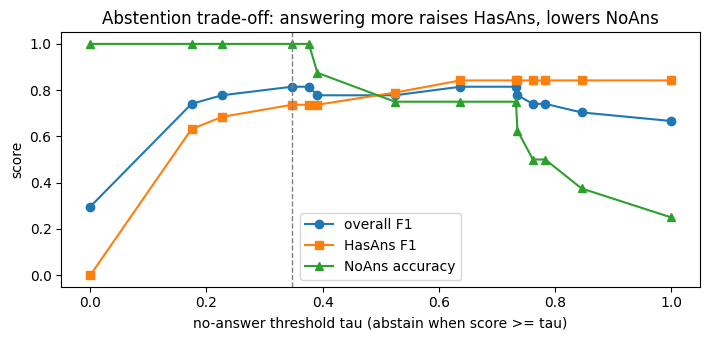

In [7]:
finite = sw[np.isfinite(sw["tau"])]
fig, ax = plt.subplots(figsize=(7.2, 3.5))
ax.plot(finite["tau"], finite["F1"], "o-", label="overall F1")
ax.plot(finite["tau"], finite["HasAns_F1"], "s-", label="HasAns F1")
ax.plot(finite["tau"], finite["NoAns_acc"], "^-", label="NoAns accuracy")
ax.axvline(best_row["tau"], color="gray", ls="--", lw=1)
ax.set_xlabel("no-answer threshold tau (abstain when score >= tau)"); ax.set_ylabel("score"); ax.legend()
ax.set_title("Abstention trade-off: answering more raises HasAns, lowers NoAns")
plt.tight_layout(); plt.show()

In [8]:
# Where does the from-scratch system fail? (at the best threshold)
res, em_v, f1_v = evaluate_v2(preds_scratch, nas_scratch, best_row["tau"])
final_scratch = [("" if na >= best_row["tau"] else p) for p, na in zip(preds_scratch, nas_scratch)]
err = pd.DataFrame({"question": [it["question"] for it in ITEMS], "prediction": final_scratch,
                    "gold": [it["answers"][0] if it["answers"] else "(none)" for it in ITEMS], "EM": em_v, "F1": f1_v})
display(err[err["EM"] < 1].reset_index(drop=True))
print(f"{int((err['EM'] < 1).sum())} of {len(err)} questions are not exact matches.")
print("Each failure is a wrong sentence (coreference: 'It was designed by...') or a wrong span, so EM and F1 agree here.")
print("Partial credit (0 < F1 < 1) appears when a span is almost right, as in the 'Barack Obama' example of Part 2.")

,question,prediction,gold,EM,F1
0,Who designed the Harbour Bridge?,,Lucia Ferreira,0.0,0.0
1,How long is the bridge?,1932,503 metres,0.0,0.0
2,Which river does the bridge cross?,,Tern River,0.0,0.0
3,Which pigment makes plants green?,,chlorophyll,0.0,0.0
4,What gas is released as a by-product?,,oxygen,0.0,0.0


5 of 27 questions are not exact matches.
Each failure is a wrong sentence (coreference: 'It was designed by...') or a wrong span, so EM and F1 agree here.
Partial credit (0 < F1 < 1) appears when a span is almost right, as in the 'Barack Obama' example of Part 2.


## Part 5: A real QA model on Colab (RoBERTa fine-tuned on SQuAD 2.0)

`deepset/roberta-base-squad2` is trained to extract an answer span **or** say "no answer". We decode it by hand (best span + the "null" score from the first token), so the code does not depend on any pipeline API. If the model cannot be downloaded, the cell uses the from-scratch system as a stand-in.

In [9]:
MODEL_FN, MODEL_NAME = scratch_qa, "from-scratch QA (stand-in for the neural model)"
if USE_MODELS:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForQuestionAnswering
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        NAME = "deepset/roberta-base-squad2"
        qa_tok = AutoTokenizer.from_pretrained(NAME)
        qa_model = AutoModelForQuestionAnswering.from_pretrained(NAME).to(dev).eval()

        def neural_qa(question, passage, max_answer_len=30):
            enc = qa_tok(question, passage, return_tensors="pt", truncation="only_second", max_length=384, return_offsets_mapping=True)
            offsets = enc.pop("offset_mapping")[0].tolist()
            seq_ids = enc.sequence_ids(0)
            with torch.no_grad():
                out = qa_model(**{k: v.to(dev) for k, v in enc.items()})
            s, e = out.start_logits[0].cpu().numpy(), out.end_logits[0].cpu().numpy()
            ctx = [i for i, sid in enumerate(seq_ids) if sid == 1]
            best = (-1e9, ctx[0], ctx[0])
            for i in ctx:
                for j in ctx:
                    if i <= j < i + max_answer_len and s[i] + e[j] > best[0]:
                        best = (s[i] + e[j], i, j)
            null = s[0] + e[0]                                   # score of the <s> token = "no answer"
            text = passage[offsets[best[1]][0]: offsets[best[2]][1]]
            return text, float(null - best[0])                   # higher = more likely unanswerable

        neural_qa("Who designed the bridge?", PASSAGES["bridge"])   # smoke test
        MODEL_FN, MODEL_NAME = neural_qa, NAME
        print("Real QA model loaded:", NAME, "on", dev)
    except Exception as e:
        print(f"Neural QA model not available here ({type(e).__name__}); using the from-scratch system instead.")
print("System under test:", MODEL_NAME)

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  496MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Real QA model loaded: deepset/roberta-base-squad2 on cpu
System under test: deepset/roberta-base-squad2


In [10]:
preds_m, nas_m = predict_all(MODEL_FN)
sw_m = sweep(preds_m, nas_m)
best_m = sw_m.loc[sw_m["F1"].idxmax()]
rows_sys = {"from-scratch (best tau)": best_row}
if MODEL_FN is not scratch_qa:                       # only add a second row when a real model is in use
    rows_sys[f"{MODEL_NAME} (best tau)"] = best_m
rows_sys["always abstain"] = always
sys_table = pd.DataFrame(rows_sys).T.drop(columns=["tau"])
display(sys_table)

,EM,F1,HasAns_EM,HasAns_F1,NoAns_acc,abstained
from-scratch (best tau),0.815,0.815,0.737,0.737,1.0,0.444
deepset/roberta-base-squad2 (best tau),1.000,1.000,1.000,1.000,1.0,0.296
always abstain,0.296,0.296,0.000,0.000,1.0,1.000


## Part 6: Why exact match fails with LLM-style answers

Modern language models answer in **full, fluent sentences**. The gold answer is a short span, so EM is almost always 0 even when the answer is right. Kamalloo et al. (2023) measured this on Natural Questions: InstructGPT scored **12.6% EM** but humans judged **71.4%** correct.

We reproduce the effect on 18 hand-written LLM-style answers. **Human labels were written by us** (1 = the answer is correct, 0 = wrong or hallucinated), as a stand-in for real human annotation.

In [11]:
VERBOSE = [
 # (question, gold, prediction, human_correct)
 ("Who designed the Harbour Bridge?", "Lucia Ferreira", "The Harbour Bridge was designed by the engineer Lucia Ferreira.", 1),
 ("When did the bridge open?", "1932", "It opened in 1932, after six years of construction.", 1),
 ("How long is the bridge?", "503 metres", "About 503 m.", 1),
 ("How much did the 2011 renovation cost?", "85 million euros", "The renovation cost 85 million euros.", 1),
 ("Which river does the bridge cross?", "Tern River", "The Tern.", 1),
 ("Who designed the Harbour Bridge?", "Lucia Ferreira", "Lucia Ferreira and her team.", 1),
 ("Where does photosynthesis mainly take place?", "chloroplasts", "In the chloroplasts of plant cells.", 1),
 ("Which pigment makes plants green?", "chlorophyll", "Chlorophyll, a green pigment.", 1),
 ("What gas is released as a by-product?", "oxygen", "Carbon dioxide.", 0),
 ("Who first described photosynthesis in detail?", "Jan Ingenhousz", "Ingenhousz, in 1779.", 1),
 ("Who founded Nordic Rail?", "Henrik Larsen", "Nordic Rail was founded by Henrik Larsen in Oslund in 1954.", 1),
 ("How many trains does the company operate?", "310", "It operates 310 trains on 28 routes.", 1),
 ("How many trains does the company operate?", "310", "It operates 280 trains.", 0),
 ("When did the headquarters move to Brenna?", "1987", "In 1954.", 0),
 ("How many passengers did it carry in 2019?", "95 million", "Around 95 million passengers travelled in 2019.", 1),
 ("How large is Lake Tessel?", "1,240 square kilometres", "About 1240 km2.", 1),
 ("How deep is the deepest point?", "310 metres", "More than 300 metres deep.", 0),
 ("How often does the lake freeze completely?", "about once every ten years", "Roughly every decade.", 1),
]
VD = pd.DataFrame(VERBOSE, columns=["question", "gold", "prediction", "human"])
print(len(VD), "answers;", VD["human"].sum(), "judged correct by the author (", f"{VD['human'].mean():.1%}", ")")
display(VD[["question", "prediction", "human"]].head(6))

18 answers; 14 judged correct by the author ( 77.8% )


,question,prediction,human
0,Who designed the Harbour Bridge?,The Harbour Bridge was designed by the engineer Lucia Ferreira.,1
1,When did the bridge open?,"It opened in 1932, after six years of construction.",1
2,How long is the bridge?,About 503 m.,1
3,How much did the 2011 renovation cost?,The renovation cost 85 million euros.,1
4,Which river does the bridge cross?,The Tern.,1
5,Who designed the Harbour Bridge?,Lucia Ferreira and her team.,1


In [12]:
# Automatic judgements, from the strictest to the most lenient
def numbers(s):
    vals = set()
    for m in re.finditer(r"(\d[\d,]*(?:\.\d+)?)\s*(million|billion)?", s.lower()):
        v = float(m.group(1).replace(",", ""))
        vals.add(v * {"million": 1e6, "billion": 1e9}.get(m.group(2), 1))
    return vals

def contains_match(pred, gold):
    return float(f" {normalize_answer(gold)} " in f" {normalize_answer(pred)} ")

def equivalent(pred, gold):
    # numbers must match exactly (85 million = 85,000,000); otherwise at least half of the gold content tokens must appear
    gn = numbers(gold)
    if gn:
        return float(gn <= numbers(pred))
    g = {stem(w) for w in normalize_answer(gold).split() if w not in STOP}
    p = {stem(w) for w in normalize_answer(pred).split()}
    return float(len(g & p) / len(g) >= 0.5) if g else 0.0

VD["EM"] = [em_pair(p, g) for p, g in zip(VD["prediction"], VD["gold"])]
VD["F1>=0.5"] = [float(f1_pair(p, g) >= 0.5) for p, g in zip(VD["prediction"], VD["gold"])]
VD["contains"] = [contains_match(p, g) for p, g in zip(VD["prediction"], VD["gold"])]
VD["equivalence rules"] = [equivalent(p, g) for p, g in zip(VD["prediction"], VD["gold"])]
VD["F1"] = [f1_pair(p, g) for p, g in zip(VD["prediction"], VD["gold"])]
display(VD[["prediction", "human", "EM", "F1", "contains", "equivalence rules"]])

,prediction,human,EM,F1,contains,equivalence rules
0,The Harbour Bridge was designed by the engineer Lucia Ferreira.,1,0.0,0.400,1.0,1.0
1,"It opened in 1932, after six years of construction.",1,0.0,0.200,1.0,1.0
2,About 503 m.,1,0.0,0.400,0.0,1.0
3,The renovation cost 85 million euros.,1,0.0,0.750,1.0,1.0
4,The Tern.,1,0.0,0.667,0.0,1.0
5,Lucia Ferreira and her team.,1,0.0,0.571,1.0,1.0
6,In the chloroplasts of plant cells.,1,0.0,0.333,1.0,1.0
7,"Chlorophyll, a green pigment.",1,0.0,0.500,1.0,1.0
8,Carbon dioxide.,0,0.0,0.000,0.0,0.0
9,"Ingenhousz, in 1779.",1,0.0,0.400,0.0,1.0


In [13]:
# Optional LLM judge (Colab): a small instruction-tuned model answers "same information? yes/no"
JUDGE_NAME = None
if USE_MODELS:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        jdev = "cuda" if torch.cuda.is_available() else "cpu"
        jt = AutoTokenizer.from_pretrained("google/flan-t5-base")
        jm = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base").to(jdev).eval()
        def llm_judge(question, gold, pred):
            prompt = (f"Question: {question}\nReference answer: {gold}\nStudent answer: {pred}\n"
                      "Does the student answer give the same information as the reference answer? Answer yes or no.")
            enc = jt(prompt, return_tensors="pt", truncation=True, max_length=512).to(jdev)
            with torch.no_grad():
                out = jm.generate(**enc, max_new_tokens=3)
            return float(jt.decode(out[0], skip_special_tokens=True).strip().lower().startswith("yes"))
        VD["LLM judge"] = [llm_judge(q, g, p) for q, g, p in zip(VD["question"], VD["gold"], VD["prediction"])]
        JUDGE_NAME = "LLM judge"
        print("LLM judge (flan-t5-base) ran on", len(VD), "answers.")
    except Exception as e:
        print(f"LLM judge not available here ({type(e).__name__}); the table below shows the rule-based metrics only.")
else:
    print("USE_MODELS is False: skipping the LLM judge.")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

LLM judge (flan-t5-base) ran on 18 answers.


,estimated system accuracy,agreement with human,Cohen kappa
metric,,,
EM,0.000,0.222,0.000
F1>=0.5,0.222,0.444,0.151
contains,0.500,0.722,0.444
equivalence rules,0.722,0.944,0.852
LLM judge,0.889,0.778,0.217
HUMAN (reference),0.778,1.000,1.000


Cohen's kappa from scratch matches scikit-learn.

Exact match says the system is 0% correct. Humans say 78%. EM badly underestimates a fluent system.


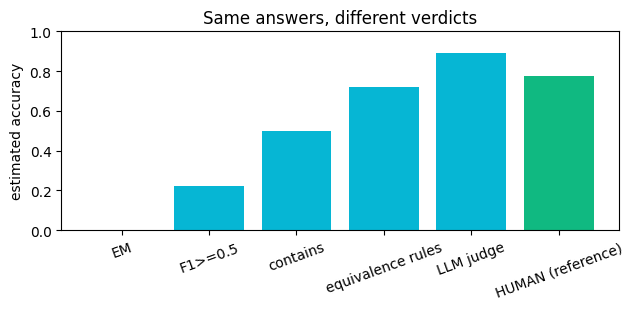

In [14]:
metrics = ["EM", "F1>=0.5", "contains", "equivalence rules"] + (["LLM judge"] if "LLM judge" in VD else [])
rows = []
for m in metrics:
    acc = (VD[m] == VD["human"]).mean()
    kappa = cohen_kappa_score(VD["human"], VD[m])
    rows.append([m, VD[m].mean(), acc, kappa])
agree = pd.DataFrame(rows, columns=["metric", "estimated system accuracy", "agreement with human", "Cohen kappa"]).set_index("metric")
agree.loc["HUMAN (reference)"] = [VD["human"].mean(), 1.0, 1.0]
display(agree)

# kappa from scratch, checked against scikit-learn
def kappa_scratch(a, b):
    a, b = np.asarray(a), np.asarray(b)
    po = (a == b).mean()
    pe = sum((a == c).mean() * (b == c).mean() for c in set(a) | set(b))
    return (po - pe) / (1 - pe) if pe < 1 else 1.0
for m in metrics:
    assert abs(kappa_scratch(VD["human"], VD[m]) - cohen_kappa_score(VD["human"], VD[m])) < 1e-9
print("Cohen's kappa from scratch matches scikit-learn.")
em_est = VD["EM"].mean()
print(f"\nExact match says the system is {em_est:.0%} correct. Humans say {VD['human'].mean():.0%}. EM badly underestimates a fluent system.")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
vals = agree["estimated system accuracy"]
ax.bar(vals.index, vals.values, color=["#ef4444"] + ["#06b6d4"] * (len(vals) - 2) + ["#10b981"])
ax.set_ylim(0, 1); ax.set_ylabel("estimated accuracy"); plt.xticks(rotation=20); ax.set_title("Same answers, different verdicts")
plt.tight_layout(); plt.show()

**Reading the table**

* **EM** rejects almost everything (verbose answers never equal the short gold span): kappa near 0.
* **F1 >= 0.5** is also hurt by long answers (precision is low).
* **contains** and **equivalence rules** are much closer to the human labels. The rules still miss paraphrases such as *"Roughly every decade"* = *"about once every ten years"*, and they would wrongly accept a half-matching name. A **semantic matcher or LLM judge** handles these, but can accept hallucinations, so humans remain the reference.
* **Kappa** corrects the raw agreement for chance, which is why it is more demanding than accuracy.

## Part 7: Metrics for retrieval-augmented QA (RAGAS-style)

A RAG system retrieves context and then answers. **RAGAS** (Es et al., 2024) scores it **without a reference answer**, using an LLM. Here are simple **lexical proxies** that show the idea and run offline (the real RAGAS uses an LLM and embeddings):

| Metric | Question it answers | Our proxy |
|---|---|---|
| **Faithfulness** | is every claim in the answer supported by the context? | share of answer content words found in the retrieved context |
| **Answer relevance** | does the answer address the question? | TF-IDF cosine between question and answer |
| **Context precision** | is the retrieved context on topic? | share of retrieved sentences that contain a question word |
| **Context recall** | does the context contain the gold answer? | 1 if the gold answer appears in the context |

In [15]:
def rag_metrics(question, answer, contexts, gold):
    ctx_words = set(re.findall(r"[a-z0-9]+", " ".join(contexts).lower()))
    ans_words = [w for w in re.findall(r"[a-z0-9]+", answer.lower()) if w not in STOP]
    faith = float(np.mean([w in ctx_words for w in ans_words])) if ans_words else 0.0
    vec = TfidfVectorizer().fit([question, answer])
    X = vec.transform([question, answer])
    rel = float((X[0] @ X[1].T).toarray()[0, 0])
    qw = set(content_words(question))
    prec = float(np.mean([bool(qw & set(content_words(c))) for c in contexts])) if contexts else 0.0
    rec = float(any(normalize_answer(gold) in normalize_answer(c) for c in contexts))
    return dict(faithfulness=faith, answer_relevance=rel, context_precision=prec, context_recall=rec)

q, gold = "How many trains does the company operate?", "310 trains"
good_ctx = ["The company started with 12 locomotives and now operates 310 trains on 28 routes.", "Its headquarters moved to Brenna in 1987."]
bad_ctx = ["The lake is fed by three rivers and drains into the sea through the Orla River.", "The deepest point of the lake is 310 metres."]
scen = {
    "A: good context, faithful answer": (q, "The company operates 310 trains.", good_ctx),
    "B: good context, HALLUCINATED answer": (q, "The company operates 450 high speed trains across Europe.", good_ctx),
    "C: wrong context, correct answer (from memory)": (q, "The company operates 310 trains.", bad_ctx),
}
table_rag = pd.DataFrame({k: rag_metrics(*v, gold) for k, v in scen.items()}).T
display(table_rag)
print("A is healthy. B stays on topic but faithfulness falls (the answer invents 450 trains and Europe).")
print("C gives the right answer but from the wrong context: context precision and recall are 0, so it is NOT grounded.")

,faithfulness,answer_relevance,context_precision,context_recall
"A: good context, faithful answer",1.000,0.345,0.5,1.0
"B: good context, HALLUCINATED answer",0.375,0.236,0.5,1.0
"C: wrong context, correct answer (from memory)",0.250,0.345,0.0,0.0


A is healthy. B stays on topic but faithfulness falls (the answer invents 450 trains and Europe).
C gives the right answer but from the wrong context: context precision and recall are 0, so it is NOT grounded.


## Part 8: Bootstrap confidence intervals

With 27 questions, a difference of a few points is noise. We resample the questions with replacement.

In [16]:
def bootstrap_ci(values, B=2000, seed=0, alpha=0.05):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = [values[rng.integers(0, len(values), len(values))].mean() for _ in range(B)]
    return values.mean(), np.quantile(means, alpha / 2), np.quantile(means, 1 - alpha / 2)

_, em_s, f1_s = evaluate_v2(preds_scratch, nas_scratch, best_row["tau"])
_, em_m, f1_m = evaluate_v2(preds_m, nas_m, best_m["tau"])
rows = []
pairs = [("from-scratch EM", em_s), ("from-scratch F1", f1_s)]
if MODEL_FN is not scratch_qa:
    pairs += [(f"{MODEL_NAME} EM", em_m), (f"{MODEL_NAME} F1", f1_m)]
for name, arr in pairs:
    m, lo, hi = bootstrap_ci(arr)
    rows.append([name, m, lo, hi])
display(pd.DataFrame(rows, columns=["metric", "mean", "CI low", "CI high"]).set_index("metric"))
print("Wide intervals: 27 questions are far too few to rank similar systems. Real benchmarks have thousands.")

,mean,CI low,CI high
metric,,,
from-scratch EM,0.815,0.667,0.963
from-scratch F1,0.815,0.667,0.963
deepset/roberta-base-squad2 EM,1.000,1.000,1.000
deepset/roberta-base-squad2 F1,1.000,1.000,1.000


Wide intervals: 27 questions are far too few to rank similar systems. Real benchmarks have thousands.


## Summary

| Metric | What it measures | Blind spot (seen here) |
|---|---|---|
| Exact match | normalised string equality | fluent or verbose correct answers score 0 |
| Token F1 | token overlap, partial credit | long answers lose precision; no semantics |
| HasAns / NoAns, best_f1 | answering and abstaining | needs a calibrated no-answer score |
| Contains / equivalence | lenient string and number matching | paraphrases, half-correct names |
| LLM judge + kappa | semantic correctness, agreement with humans | can accept hallucinations; validate on human labels |
| Faithfulness, relevance, context recall | grounding of RAG answers | lexical proxies here; the real ones use an LLM |

**Exercises**

1. Add 5 questions of your own (some unanswerable) and re-run the SQuAD 2.0 table.
2. Make the from-scratch system abstain only when the **extracted answer is empty** and compare with the threshold approach.
3. Add a metric **"EM after alias expansion"** (for example *USA* = *United States*) and measure how it changes the verbose-answer table.
4. On Colab, replace `flan-t5-base` by `flan-t5-large` as the judge and compare kappa.
5. Load 50 questions of SQuAD 2.0 with `datasets` (`rajpurkar/squad_v2`) and evaluate the neural model with the official `evaluate` library.

**References:** Rajpurkar et al. (2016) SQuAD; Rajpurkar et al. (2018) SQuAD 2.0; Kamalloo et al. (2023) evaluating open-domain QA in the era of LLMs; Lin et al. (2022) TruthfulQA; Es et al. (2024) RAGAs.